# 如何建立最小二乘模型

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

同一组下降曲线，可以用直线、指数或高阶多项式去拟合。算法会认真地完成你给它的目标，哪怕目标建立错了。本章先把“观测、输入、参数和误差”分清楚。

## 先写出观测方程

一个常见模型是$y_i=f(t_i,x)+\varepsilon_i$。$t_i$是已知输入，$y_i$是测量结果，$x\in\mathbb R^n$是待估参数。将所有模型值减去观测，构成$r(x)\in\mathbb R^m$。

$$r_i(x)=f(t_i,x)-y_i,\qquad x^*=\arg\min_x\frac12\|r(x)\|^2.$$

通常希望$m\ge n$，但观测数量够多并不能保证参数唯一可辨。若两列参数影响几乎相同，增加重复观测也可能无济于事。参数是否可辨识取决于模型对它们的不同响应。

## “线性”指的是对未知参数线性

$a+bt+ct^2$对$t$是曲线，但对未知的$(a,b,c)$是线性的。相反，$a\exp(-kt)+c$对$k$是非线性的。若$k$已知，只估$a,c$，问题又变成线性。这一区分决定了能否一次线性求解，还是需要迭代。

truth: [2.5 0.8 0.4] estimate: [2.51287 0.82961 0.42906]
residual shape: (35,) parameter shape: (3,)


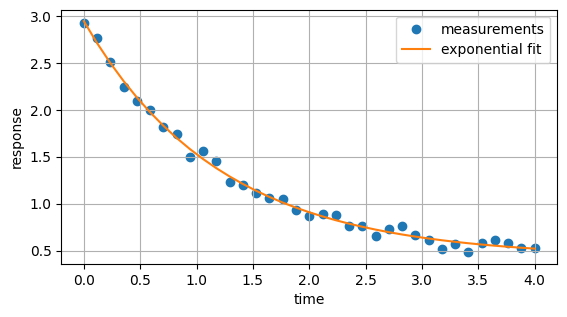

In [2]:
t = np.linspace(0, 4, 35)
rng = np.random.default_rng(102)
truth = np.array([2.5, .8, .4])
def model(p):
    a, k, c = p
    return a*np.exp(-k*t)+c
y = model(truth)+rng.normal(0, .04, len(t))
def residual(p):
    return model(p)-y
fit = least_squares(residual, [2., .5, .2], bounds=([0, 0, -np.inf], np.inf))
print('truth:', truth, 'estimate:', fit.x)
print('residual shape:', residual(fit.x).shape, 'parameter shape:', fit.x.shape)
plt.scatter(t, y, label='measurements')
plt.plot(t, model(fit.x), color='C1', label='exponential fit')
plt.xlabel('time'); plt.ylabel('response'); plt.legend(); plt.show()

## 单位不同的残差不能直接相加

若一个传感器给出毫米，另一个给出伏特，直接把两个残差平方相加，等于用单位选择隐含地决定谁更重要。常用做法是按噪声标准差归一化：$\tilde r_i=r_i/\sigma_i$。这既统一量纲，也让高噪声观测少一些影响。相关误差需要整体白化，见第05章。

不要通过对$y-c$取对数，未经说明就把指数模型变成直线：$\log(y-c)$会改变误差分布和权重，而且当$y\le c$时根本没有实数定义。变换模型和变换损失是两件事。

## 最小值与可用答案的距离

残差小，可能是模型合理，也可能是参数太多。参数拟合得好，还可能在观测区间外预测很差。应该分别问：训练数据解释得怎样？未参与拟合的数据预测怎样？参数的物理范围是否合理？最终控制目标是否可达？

## 练习与解答

练习：$a\sin(t)+b\cos(t)$、$\sin(at+b)$、$a/(1+bt)$中哪些是线性最小二乘模型？解答：只有第一个对未知参数线性；其设计矩阵两列分别是$\sin(t_i)$和$\cos(t_i)$。

练习：把残差从$f-y$改为$y-f$，但仍使用原来的雅可比会怎样？解答：残差与导数符号不一致，梯度方向反转，算法可能不断拒绝步长。必须同时将雅可比乘$-1$。

练习：令全部$t_i=0$，上面的指数模型能估计哪些参数？解答：只能估计$a+c$；$k$对预测完全没有作用，$a$和$c$也无法分开。